# Laboratorium 1

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from typing import List
import random

from Utils.round_robin import round_robin
from Utils.sjf import sjf, srtf
from Utils.proces import Process
from Utils.fcfs import fcfs

## Generowanie procesów & Addons

In [63]:
PROCESS_NUMBER = 50
RR_TIME_QUANT = 500

EXEC_TIME_MEAN = 100
EXEC_TIME_VARIANCE = 25

PROCESS_GENERATION_FACTOR = 0

def generate_processes(num_processes: int) -> List[Process]:
    processes = []
    for i in range(num_processes):
        exec_time = round(random.gauss(mu=EXEC_TIME_MEAN, sigma=EXEC_TIME_VARIANCE))
        processes.append(Process(i+1, exec_time))
    return processes


def get_outcome_average(data: List[Process]) -> float:
    return sum(x.waiting_time for x in data) / sum(1 for x in data if x.executed)

## Symulacja i podsumowanie

Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0


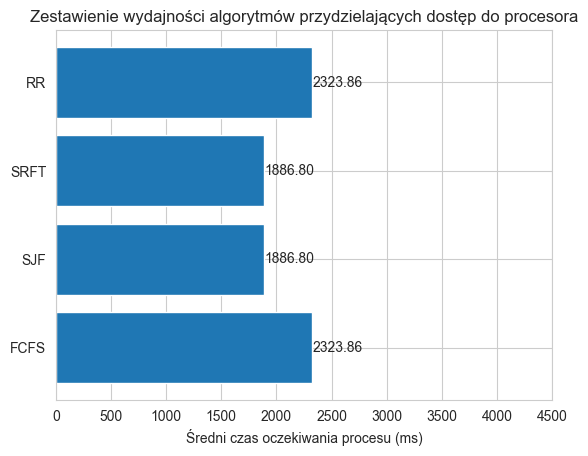

In [64]:
sim_data = generate_processes(PROCESS_NUMBER)

res_fcfs = get_outcome_average(fcfs(sim_data, PROCESS_GENERATION_FACTOR))
res_sjf = get_outcome_average(sjf(sim_data, PROCESS_GENERATION_FACTOR))
res_srtf = get_outcome_average(srtf(sim_data, PROCESS_GENERATION_FACTOR))
res_round_robin = get_outcome_average(round_robin(sim_data, RR_TIME_QUANT))

np.random.seed(19680801)

people = ('FCFS', 'SJF', 'SRFT', 'RR')[::-1]
y_pos = np.arange(len(people))
error = np.random.rand(len(people))

fig, ax = plt.subplots()

hbars = ax.barh(y_pos, [res_fcfs, res_sjf, res_srtf, res_round_robin], xerr=error, align='center')
ax.set_yticks(y_pos, labels=people)
ax.invert_yaxis()
ax.set_xlabel('Średni czas oczekiwania procesu (ms)')
ax.set_title('Zestawienie wydajności algorytmów przydzielających dostęp do procesora')

ax.bar_label(hbars, fmt='%.2f')
ax.set_xlim(right=4500)

plt.show()

## Walidacja rezultatów dla zwielokrotnionej próby, róznego zestawu danych

Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0
Liczba dynamicznie dodanych procesów: 0


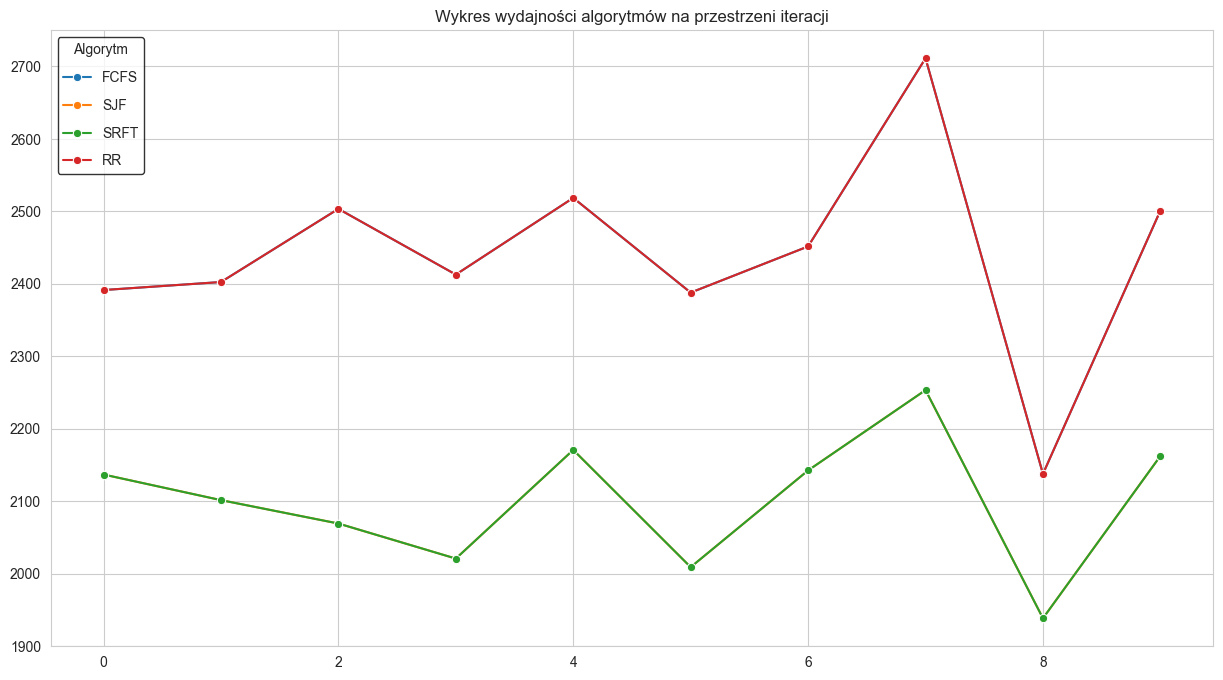

In [65]:
arr_fcfs = []
arr_sjf = []
arr_srtf = []
arr_rr = []

for i in range(10):
    test_data = generate_processes(PROCESS_NUMBER)
    arr_fcfs.append(get_outcome_average(fcfs(test_data, PROCESS_GENERATION_FACTOR)))
    arr_sjf.append(get_outcome_average(sjf(test_data, PROCESS_GENERATION_FACTOR)))
    arr_srtf.append(get_outcome_average(srtf(test_data, PROCESS_GENERATION_FACTOR)))
    arr_rr.append(get_outcome_average(round_robin(test_data, RR_TIME_QUANT)))

plt.figure(figsize=(15,8))
sns.set_style('whitegrid')
sns.lineplot(arr_fcfs, marker='o', label="FCFS")
sns.lineplot(arr_sjf, marker='o', label="SJF")
sns.lineplot(arr_srtf, marker='o', label="SRFT")
sns.lineplot(arr_rr, marker='o', label="RR")
plt.title("Wykres wydajności algorytmów na przestrzeni iteracji")
plt.legend(title="Algorytm", loc='upper left', edgecolor='black', labelspacing=1)
plt.show()